# Molecular Waves and Spectra: Physical Background, Equations, and Computational Cost

## What this notebook actually computes

There are separate analysis branches here, not one end-to-end simulation. First, a digitized methane infrared (IR) transmittance spectrum from the NIST Chemistry WebBook is parsed, plotted, and searched for candidate absorption minima. A four-parameter damped-cosine curve is fitted only as a generic shape surrogate. A separate slider demonstration constructs an explicitly synthetic space-time field; it does not solve for methane. Finally, the equation-driven viewer has an optional PySCF density-functional-theory (DFT) calculation: given an explicit starting geometry, charge, and spin multiplicity, it optimizes nuclear coordinates and computes an approximate electronic state. The NIST fit is not used as input to that quantum-chemistry calculation.

A measured IR absorption at wavenumber $\tilde\nu$ (in cm$^{-1}$) corresponds to photon energy $E_\gamma=hc\tilde\nu$ and angular frequency $\omega_\gamma=2\pi c\tilde\nu$. Molecular absorption occurs when the photon energy matches an allowed energy-level difference, subject to transition selection rules. The digitized NIST curve is a measured transmission trace, not a spatial electron-density image or a time-resolved molecular trajectory.

## Step 1 — Read and interpret the public spectrum

The JCAMP-DX loader reads the NIST `XYDATA` block. It applies the file scale factors to each row, reconstructs each wavenumber as $\tilde\nu_j=x_0+j\,\Delta x$, removes non-finite or non-positive transmission values, and verifies that the surviving axis is strictly increasing. The file contains $N=3{,}583$ digitized samples spanning approximately 449.47–3,801.32 cm$^{-1}$. The independent variable is wavenumber; the reported measurement is transmittance $T=I/I_0$, a dimensionless intensity ratio.

For display, the notebook computes apparent absorbance $A_{10}=-\log_{10}T$. This logarithmic transform makes absorption bands appear upward rather than as transmission dips. It is not baseline-corrected, and without the needed path length, concentration, calibration, and background trace it should not be treated as a calibrated molar absorptivity. The original NIST source describes a gas-phase spectrum digitized from a historical hard-copy trace, so digitization and instrumental resolution limit the precision of individual samples.

## Step 2 — Find candidate absorption features

The peak routine searches for local maxima in $-T$, which are local minima in the measured transmittance. The prominence threshold is 0.003 transmittance units and the minimum spacing is 20 samples; these are signal-processing settings, not physical constants. The largest eight detected prominences are reported with their measured wavenumbers. A candidate minimum is not automatically a distinct normal mode: overlapping bands, baseline structure, finite resolution, and noise can shift or merge minima. Mode assignment requires a vibrational calculation or external spectroscopic assignment evidence.

## Step 3 — Fit a deliberately generic curve

The wavenumber axis is normalized to $x=(\tilde\nu-\tilde\nu_{\min})/(\tilde\nu_{\max}-\tilde\nu_{\min})\in[0,1]$. With the selected oscillator family, the fitted prediction is

$$\widehat T(x)=A e^{-\gamma x}\cos(\omega x)+c,$$

where $A,\gamma,\omega,c$ are numerical fit coefficients. `curve_fit` chooses them to approximately minimize $\sum_{j=1}^N[T_j-\widehat T(x_j)]^2$. Because $x$ is normalized and the response is transmission rather than a displacement coordinate, these coefficients are not a molecular vibrational frequency, lifetime, force constant, mass, or Hamiltonian parameter. The reported RMSE and $R^2$ describe only this four-parameter approximation to this trace; they do not validate the oscillator as a molecular model. The notebook's saved fit has low explanatory power ($R^2\approx0.19$), consistent with using one smooth damped cosine for a many-feature spectrum.

## Step 4 — Derive the ideal one-mode oscillator (theory, not a fit to NIST)

Near a stable equilibrium, a single small normal-coordinate displacement $q$ has a quadratic potential: $V(q)\simeq V(0)+\tfrac12 kq^2$, where $k=\partial^2V/\partial q^2|_{0}>0$. For a Cartesian displacement measured in metres, $m$ is in kg and $k$ in N/m (kg/s$^2$); $\omega_0=\sqrt{k/m}$ is in rad/s. After subtracting the irrelevant constant $V(0)$, its kinetic energy is $T=\tfrac12 m\dot q^2$, and $L=T-V=\tfrac12m\dot q^2-\tfrac12kq^2$. Applying $\frac{d}{dt}\frac{\partial L}{\partial\dot q}-\frac{\partial L}{\partial q}=0$ gives $m\ddot q+kq=0$ and conserved energy $E=\tfrac12m\dot q^2+\tfrac12kq^2$.

The Legendre transform uses canonical momentum $p=\partial L/\partial\dot q=m\dot q$ and gives $H=p\dot q-L=p^2/(2m)+kq^2/2$. Hamilton's equations, $\dot q=\partial H/\partial p=p/m$ and $\dot p=-\partial H/\partial q=-kq$, recover the same oscillator equation. This derivation explains an ideal conservative mode. It is not numerically solved by the generic curve fit, and it does not supply a measured $m$, $k$, or methane mode assignment. Real polyatomic vibrations require multiple coupled coordinates; their harmonic frequencies come from eigenvalues of the mass-weighted Hessian of molecular potential energy at an equilibrium geometry.

## Step 5 — Understand what the synthetic field control does

The field widget is a deterministic teaching construction. If a global four-dimensional `field4d` or `q` array exists, that array is used; otherwise the fallback takes signal samples $s_i$ (in this notebook, transmittance), replaces non-finite entries, standardizes the series, and interpolates it to $T=36$ time indices. It multiplies those values by a fixed separable spatial pattern on a $10\times10\times6$ grid:

$$q_0(i,j,k,l)=s_i\cos x_j\cos y_k\cos z_l,\qquad x_j,y_k,z_l\in[0,2\pi).$$

At each point it then forms the algebraic combination $q_{\rm sim}=e^{-\gamma t}q_0\cos(ct+\phi)+F\sin(\Omega t+\phi)\sin x\cos y\sin z+\alpha q_0^3/(1+|q_0|^2)-v\,\partial_xq_0$, where the sampled $t,x,y,z$ axes all span $[0,2\pi)$ and are dimensionless. A six-neighbor periodic stencil is applied as $q\leftarrow q+D\nabla^2_{\rm stencil}q-\kappa q$. `np.roll` makes opposite grid edges neighbors, so this stencil imposes periodic boundary conditions. The code does not divide finite differences by physical $\Delta x^2$, `np.gradient` differentiates per array index rather than per calibrated time or length, and it does not advance a discretized PDE through time steps. The slider coefficients and axes therefore have no calibrated molecular units.

Here $p_{\rm sim}$ is simply `np.gradient(q_sim, axis=0)`, a difference per time index, not the oscillator's canonical momentum. The quantity labeled energy is a model proxy, $e_{\rm proxy}=\tfrac12p_{\rm sim}^2+\tfrac12|\nabla_{\rm index}q|^2+\tfrac12\kappa q^2$, evaluated on one selected slice; it is not a conserved Hamiltonian or measured molecular energy. The probe is one grid cell plus a seeded synthetic noise sequence, and its FFT reports frequency bins in index units (`d=1`), not cm$^{-1}$. This branch illustrates how chosen terms alter an invented field; it neither reconstructs a 3D/4D methane signal nor constrains the NIST fit.

## Step 6 — Optional molecular calculation: PySCF DFT

The separate DFT controls accept one Cartesian position per atom, a total charge, and an explicit spin multiplicity. Formula fixes composition and electron count $N_e=\sum_A Z_A-Q$ but does not identify an isomer or geometry; the entered coordinates are only the optimizer's starting point. The initial implementation uses the `def2-SVP` Gaussian basis (verified for H through Kr) and selects restricted Kohn–Sham (RKS) for a closed-shell singlet or unrestricted Kohn–Sham (UKS) for a nonzero spin. The spin input is $N_\alpha-N_\beta=\mathcal M-1$; an incompatible electron-count/multiplicity parity is rejected.

At fixed nuclear positions $\mathbf R$, the self-consistent Kohn–Sham equations are $[-\tfrac12\nabla^2+v_{\rm eff}[n,\mathbf R]]\psi_i=\epsilon_i\psi_i$, with density $n(\mathbf r)=\sum_i f_i|\psi_i(\mathbf r)|^2$. The selected approximate functional (B3LYP by default) defines the exchange-correlation term in the electronic total-energy functional; nuclear repulsion is also included in the total molecular energy. PySCF iterates density, effective potential/Fock matrix, and occupied orbitals to self-consistency. geomeTRIC then changes nuclear coordinates to reduce this DFT total energy, using calculated energy gradients. Bond angles are not fixed by a hand-entered angle penalty: they emerge from the optimized coordinates and the electronic-plus-nuclear energy surface. This is a local optimization, so the result can depend on the starting geometry and electronic state.

After convergence, the code evaluates the AO basis on a Cartesian real-space grid and contracts the converged density matrix to obtain $n(\mathbf r)$. The density is reported in electrons per bohr$^3$; an isosurface is only a selected visualization threshold, not a hard molecular boundary. A selected MO is $\psi_i(\mathbf r)=\sum_\mu C_{\mu i}\chi_\mu(\mathbf r)$; its signed lobes show wavefunction phase, while occupation is separately reported. The solver does not calculate vibrational frequencies, IR intensities, bond dissociation energies, or a many-body exact wavefunction, and its output is not an experimental density map. The listed close contacts/angles are a covalent-radius heuristic for display, not a quantum bond-order calculation.

## Computational complexity of the major steps

Asymptotic costs below describe the implemented operations or standard dense-basis DFT scaling, not wall-clock guarantees. Constants, vectorization, hardware, screening, convergence, and the selected grid/basis strongly affect actual runtime. Let $N$ be spectrum sample count, $L$ the input text length, $P=4$ fit parameters, $I$ nonlinear-fit iterations, $T$ time slices, $X,Y,Z$ synthetic grid dimensions, $A$ atoms, $B$ total qualitative orbitals, $M$ PySCF basis functions, $K$ SCF iterations per geometry step, $S$ geometry-optimization steps, and $G$ real-space density-grid points.

| Program step | Time complexity | Memory complexity | What controls it |
|---|---:|---:|---|
| Parse molecular formulas/equations and count atoms | $O(L)$ | $O(L)$ | Each input character/token is scanned a constant number of times; the parser caps formula nesting depth at 16. |
| Download, decode, validate, and transform the NIST trace | $O(N)$ after download | $O(N)$ | Number of digitized samples; network transfer is proportional to response size. |
| Detect transmission minima and rank the strongest | $O(N)$ | $O(N)$ | `find_peaks` scans the one-dimensional trace; ranking the eight selected features is bounded by the number of detected peaks. |
| Fit the four-parameter generic curve | Approximately $O(I N P^2+I P^3)$; with fixed $P=4$, approximately $O(IN)$ | $O(N+P^2)$ | Each least-squares iteration evaluates/residualizes all samples and updates a small parameter system; nonlinear convergence controls $I$. |
| Build and process synthetic field, finite differences, gradients, proxy energy | $O(TXYZ)$ | $O(TXYZ)$ | Full space-time array; defaults are only $36\times10\times10\times6$. The probe FFT adds $O(T\log T)$. |
| Truncated HOSVD of a 4D tensor with dimensions $n_1,\ldots,n_4$ | Full mode SVDs: $\sum_j O(n_j m_j\min(n_j,m_j))$, where $m_j=\prod_{i\ne j}n_i$; projection cost depends on retained ranks | Dense input/unfolding workspaces plus $O(\prod_j r_j+\sum_j n_jr_j)$ encoded values | Storage is reduced only when the downstream path uses the core and factor matrices without reconstructing the full tensor. Randomized/truncated SVD or streaming is needed to reduce peak memory at large scale. |
| DMD snapshot training and reduced evolution | Standard snapshot SVD $O(nm^2)$ for $n\ge m$; reduced operator construction about $O(nmr+mr^2)$; each reduced step $O(r^2)$ plus $O(nr)$ if reconstructed in full coordinates | $O(nm)$ for training snapshots; about $O(nr+r^2)$ for retained modes/operator | A speedup applies to repeated evolution after training and only when rank $r\ll\min(n,m)$; storing full snapshots during training is still expensive. |
| Qualitative molecular orbitals: evaluate $B$ orbitals on grid and form overlap matrix | $O(BG+B^2G+B^3)$ | $O(BG+B^2)$ | $G$ is approximately 180,000 grid points by default; the $B^2G$ overlap contractions and any dense MO eigensolve dominate as system size grows. |
| PySCF SCF and geometry optimization | Conservative conventional dense-basis estimate $O(SK(M^4+M^3+GM^2))$ | Typically $O(M^2+G+QM)$ plus integral work | $M$ is basis-function count; $M^3$ is dense diagonalization, $M^4$ is conventional two-electron-integral/Coulomb-exchange work, and numerical DFT quadrature/density contractions scale with $GM^2$. $Q=10{,}000$ is the AO-evaluation batch size. Screening, direct algorithms, and hardware can change practical scaling. |
| Atomic-orbital gallery field | $O(81^3)$ per selected orbital | $O(81^3)$ | Fixed $81\times81\times81$ grid (531,441 points) for the radial/angular AO field. |
| Final DFT density / one MO on the real-space grid | $O(GM^2)$ for density; $O(GM)$ for one MO | $O(G+M^2)$; the implementation batches AO evaluation in blocks of 10,000 points | Grid spacing and spatial extent determine $G$; the grid is capped at 350,000 points. |
| Contact distances and angle heuristic | $O(A^2+A^3)$ worst case | $O(A^2)$ | Pair distances are quadratic; angle enumeration is quadratic in each atom's neighbor count and can be cubic for a dense contact graph. |

The dense-basis DFT estimate is intentionally conservative: PySCF uses integral screening and numerical-grid methods, so observed cost is system- and hardware-dependent. For a fixed small molecule, the orbital basis size and SCF/geometry convergence dominate; rasterizing and plotting the final density has a separate cost proportional to the requested 3D grid size.

### Can dimensionality reduction help here?

HOSVD is appropriate for compressing a large, approximately low-multilinear-rank tensor (for example, many time snapshots of a spatially smooth density/field). For $\mathcal X\in\mathbb R^{n_1\times\cdots\times n_d}$ it stores a core of size $\prod_jr_j$ and factors with $\sum_jn_jr_j$ values, rather than $\prod_jn_j$ values. The optional benchmark below measures approximation error and this *encoded* storage on the synthetic seed. Since the built-in seed is an outer product by construction and only has 21,600 float64 entries, the result is pedagogical; it does not demonstrate that experimental spectra or molecular densities are low rank. The benchmark does not alter the full-rank simulation and includes neither end-to-end speedup nor peak-memory savings. To obtain those benefits in a large calculation, operate on compressed coordinates from the beginning or use a chunked/randomized factorization, and validate the output against the full method.

DMD (dynamic mode decomposition) instead builds a low-rank linear map $x_{k+1}\approx Ax_k$ from ordered snapshots and can efficiently approximate or forecast a trajectory after training. For $n$ spatial degrees of freedom and $m$ snapshots, a standard snapshot SVD costs about $O(nm^2)$ when $n\ge m$, followed by reduced-model evolution in rank $r$. It requires meaningful temporal samples and an approximately linear low-rank evolution over the region of interest. The notebook's synthetic widget is algebraic, not a time-stepped molecular trajectory; the NIST axis is wavenumber rather than time; and the DFT output is a stationary state. Thus DMD is not applied to these current data. A future DMD surrogate would need validated time-dependent simulation or experimental snapshots, and should be checked on held-out times/conditions.

Renderer note: Mermaid may not display in every notebook host; the Python fallback diagram below is intended to display reliably. Treat the diagram as a conceptual overview, not as evidence that the measured spectrum, synthetic field, oscillator fit, and DFT calculation form a single coupled solver.

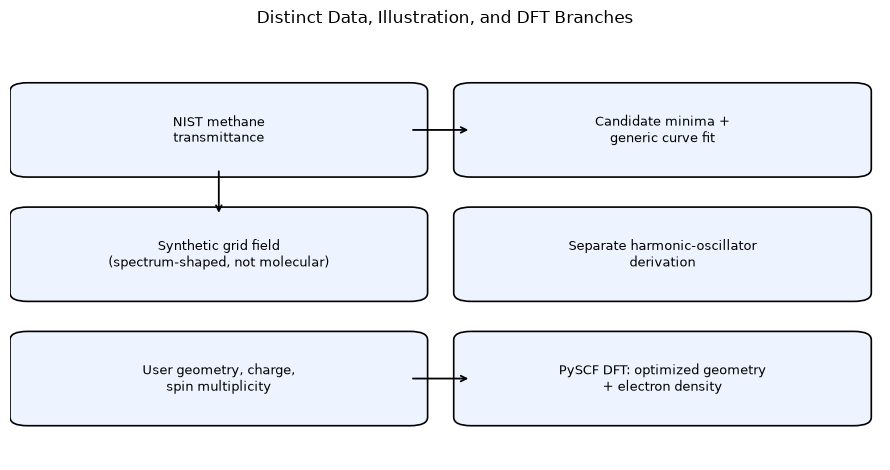

In [1]:
# Theory diagram renderer (always visible in notebooks, independent of Mermaid support).
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axis('off')
blocks = [
    (0.02, 0.68, 'NIST methane\ntransmittance'),
    (0.53, 0.68, 'Candidate minima +\ngeneric curve fit'),
    (0.02, 0.39, 'Synthetic grid field\n(spectrum-shaped, not molecular)'),
    (0.53, 0.39, 'Separate harmonic-oscillator\nderivation'),
    (0.02, 0.10, 'User geometry, charge,\nspin multiplicity'),
    (0.53, 0.10, 'PySCF DFT: optimized geometry\n+ electron density'),
]
for x0, y0, label in blocks:
    patch = FancyBboxPatch((x0, y0), 0.44, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#eef4ff')
    ax.add_patch(patch)
    ax.text(x0 + 0.22, y0 + 0.09, label, ha='center', va='center', fontsize=9)
ax.annotate('', xy=(0.53, 0.77), xytext=(0.46, 0.77), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.24, 0.57), xytext=(0.24, 0.68), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.53, 0.19), xytext=(0.46, 0.19), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Distinct Data, Illustration, and DFT Branches')
plt.tight_layout()
plt.show()

## Theory-to-code mapping and limits

### Conservative one-mode reference
For a Cartesian displacement $q$ in metres, the ideal reference has $L=\tfrac12m\dot q^2-\tfrac12kq^2$, canonical momentum $p=m\dot q$, and Hamiltonian $H=p^2/(2m)+kq^2/2$. If the Lagrangian has no explicit time dependence and no nonconservative forces, $H$ is constant; $\omega_0=\sqrt{k/m}$ is an angular frequency in rad/s. These equations establish the signs and units of an idealized vibration, but this notebook does not estimate $m$ or $k$ from the methane trace.

### What a damped oscillator would mean
A linear viscous damping model can be written with Rayleigh dissipation $\mathcal R=\tfrac12c\dot q^2$. The dissipative Euler–Lagrange equation $\frac{d}{dt}\frac{\partial L}{\partial\dot q}-\frac{\partial L}{\partial q}+\frac{\partial\mathcal R}{\partial\dot q}=0$ gives $m\ddot q+c\dot q+kq=0$. Its mechanical energy obeys $\dot E=-c\dot q^2\leq0$; it is not conserved. For the underdamped case $c^2<4mk$, the solution has envelope $e^{-\gamma t}$ with $\gamma=c/(2m)$ and oscillation frequency $\omega_d=\sqrt{k/m-\gamma^2}$. This is a reference derivation only: the spectrum fit's independent variable is normalized wavenumber $x$, not time $t$, and its coefficients are not $m,c,k$ or a measured lifetime.

### Why the numerical branches are not that oscillator
The fitted function is $A e^{-\gamma x}\cos(\omega x)+c_0$ with an offset, minimized directly against transmittance. It has no physical time axis, explicit mass, force constant, or independently measured phase. Likewise, the slider routine named `physical_action_simulation` constructs a synthetic array with algebraic terms and periodic finite differences; it does not derive a field equation from an action or integrate the damped-oscillator equation. The optional PySCF path is a separate electronic-structure calculation on user-supplied geometry. Its optimized energy surface could support a later vibrational Hessian calculation, but the current solver does not compute normal-mode frequencies or IR intensities.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
import requests
import ipywidgets as widgets
from ipywidgets import interact

plt.style.use('seaborn-v0_8-whitegrid')

DOMAIN_KEY = '16_molecular_waves'
DOMAIN_TITLE = 'Methane IR spectrum (NIST Coblentz)'
MODEL_FAMILY = 'oscillator'
DATA_SOURCES = [{
    "name": "NIST Chemistry WebBook: methane gas-phase IR spectrum",
    "url": "https://webbook.nist.gov/cgi/cbook.cgi?JCAMP=C74828&Index=1&Type=IR",
    "reference": "NIST Chemistry WebBook, SRD 69; Coblentz No. 8873, 1964; spectrum digitized by NIST"
}]

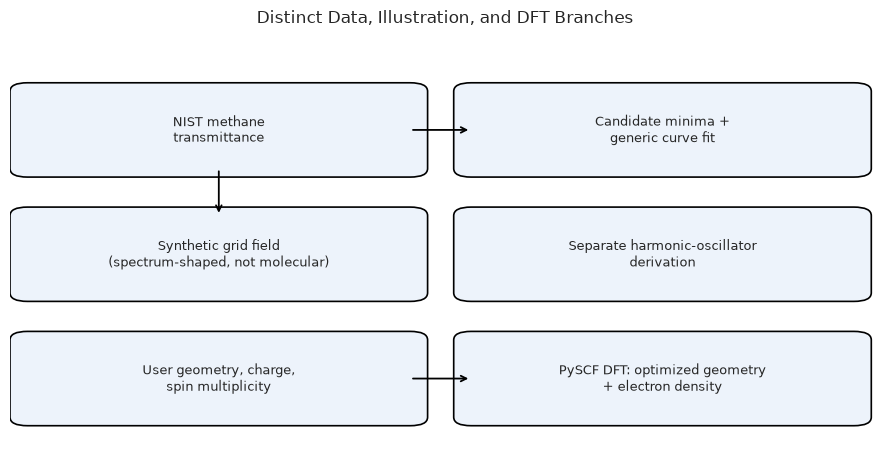

In [3]:
# Fallback model diagram renderer (works even when Mermaid is not embedded by the notebook renderer).
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axis('off')
nodes = [
    (0.02, 0.68, 'NIST methane\ntransmittance'),
    (0.53, 0.68, 'Candidate minima +\ngeneric curve fit'),
    (0.02, 0.39, 'Synthetic grid field\n(spectrum-shaped, not molecular)'),
    (0.53, 0.39, 'Separate harmonic-oscillator\nderivation'),
    (0.02, 0.10, 'User geometry, charge,\nspin multiplicity'),
    (0.53, 0.10, 'PySCF DFT: optimized geometry\n+ electron density'),
]
for x0, y0, label in nodes:
    patch = FancyBboxPatch((x0, y0), 0.44, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#edf3fb')
    ax.add_patch(patch)
    ax.text(x0 + 0.22, y0 + 0.09, label, ha='center', va='center', fontsize=9)
ax.annotate('', xy=(0.53, 0.77), xytext=(0.46, 0.77), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.24, 0.57), xytext=(0.24, 0.68), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.53, 0.19), xytext=(0.46, 0.19), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Distinct Data, Illustration, and DFT Branches')
plt.tight_layout()
plt.show()

In [4]:
def load_empirical_data():
    source = DATA_SOURCES[0]
    response = requests.get(source['url'], timeout=30)
    response.raise_for_status()

    header = {}
    wavenumber = []
    transmittance = []
    reading_xydata = False
    saw_xydata = False
    for line in response.text.splitlines():
        line = line.strip()
        if not line:
            continue
        if line.startswith('##'):
            if line.upper().startswith('##XYDATA='):
                reading_xydata = True
                saw_xydata = True
                continue
            if reading_xydata:
                break
            key, separator, value = line[2:].partition('=')
            if separator:
                header[key.upper()] = value.strip()
            continue
        if not reading_xydata:
            continue

        values = np.asarray([float(value) for value in line.split()], dtype=float)
        if values.size < 2:
            raise ValueError(f'Invalid JCAMP-DX data row: {line!r}')
        first_x = values[0] * float(header.get('XFACTOR', '1'))
        x_step = float(header['DELTAX']) * float(header.get('XFACTOR', '1'))
        y_factor = float(header.get('YFACTOR', '1'))
        wavenumber.extend(first_x + x_step * np.arange(values.size - 1))
        transmittance.extend(values[1:] * y_factor)

    if not saw_xydata or not wavenumber:
        raise ValueError('The NIST response did not contain a JCAMP-DX XYDATA spectrum.')
    wavenumber = np.asarray(wavenumber, dtype=float)
    transmittance = np.asarray(transmittance, dtype=float)
    valid = np.isfinite(wavenumber) & np.isfinite(transmittance) & (transmittance > 0)
    wavenumber = wavenumber[valid]
    transmittance = transmittance[valid]
    if wavenumber.size < 8 or np.any(np.diff(wavenumber) <= 0):
        raise ValueError('The NIST spectrum is empty, too short, or not ordered by wavenumber.')

    raw_df = pd.DataFrame({
        'wavenumber_cm1': wavenumber,
        'transmittance': transmittance,
        'apparent_absorbance': -np.log10(transmittance),
    })
    x_data = (wavenumber - wavenumber.min()) / np.ptp(wavenumber)
    return x_data, transmittance, source, raw_df

x_data, y_data, chosen_source, raw_df = load_empirical_data()
print('Loaded source:', chosen_source['name'])
print('Reference:', chosen_source['reference'])
print(f'Points: {len(raw_df)}')
print(f"Wavenumber range: {raw_df['wavenumber_cm1'].min():.2f}–{raw_df['wavenumber_cm1'].max():.2f} cm⁻¹")
print('Reported signal: gas-phase transmittance; digitized from a 1964 hard-copy spectrum')

Loaded source: NIST Chemistry WebBook: methane gas-phase IR spectrum
Reference: NIST Chemistry WebBook, SRD 69; Coblentz No. 8873, 1964; spectrum digitized by NIST
Points: 3583
Wavenumber range: 449.47–3801.32 cm⁻¹
Reported signal: gas-phase transmittance; digitized from a 1964 hard-copy spectrum


In [5]:
def model_function(x, p1, p2, p3, p4):
    if MODEL_FAMILY == 'oscillator':
        A, gamma, omega, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) * np.cos(omega * x) + c
    if MODEL_FAMILY == 'damped':
        A, gamma, _, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) + c
    if MODEL_FAMILY == 'logistic':
        K, r, x0, c = p1, p2, p3, p4
        return K / (1.0 + np.exp(-r * (x - x0))) + c
    if MODEL_FAMILY == 'michaelis':
        vmax, km, _, c = p1, p2, p3, p4
        return vmax * x / (km + x + 1e-12) + c
    if MODEL_FAMILY == 'diffusion':
        A, D, _, c = p1, p2, p3, p4
        return A * np.exp(-D * x) + c
    return p1 * x + p2

p0 = [np.nanmax(y_data) - np.nanmin(y_data), 0.5, 6.0, np.nanmean(y_data)]
bounds = ([-1e6, 0.0, -1e3, -1e6], [1e6, 50.0, 1e3, 1e6])

try:
    popt, _ = curve_fit(model_function, x_data, y_data, p0=p0, bounds=bounds, maxfev=20000)
except (RuntimeError, ValueError) as exc:
    raise RuntimeError('The generic curve-shape fit did not converge; no substitute parameters were used.') from exc

y_hat = model_function(x_data, *popt)
rmse = float(np.sqrt(np.mean((y_data - y_hat) ** 2)))
r2 = float(1.0 - np.sum((y_data - y_hat) ** 2) / max(np.sum((y_data - np.mean(y_data)) ** 2), 1e-12))

print('Generic curve-shape fit parameters (not molecular parameters):', popt)
print('RMSE:', rmse)
print('R^2:', r2)


Generic curve-shape fit parameters (not molecular parameters): [7.23880503e-02 2.05100809e-12 1.25396959e+01 9.48651558e-01]
RMSE: 0.10534824780715375
R^2: 0.19070080218867935


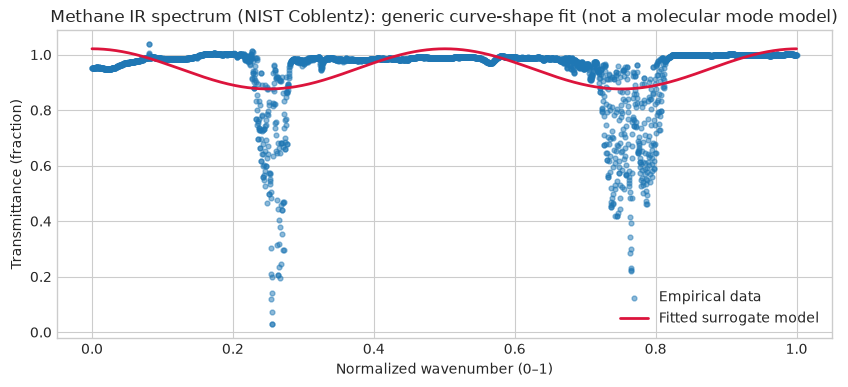

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(x_data, y_data, s=12, alpha=0.5, label='Empirical data')
ax.plot(x_data, y_hat, color='crimson', linewidth=2.0, label='Fitted surrogate model')
ax.set_title(f'{DOMAIN_TITLE}: generic curve-shape fit (not a molecular mode model)')
ax.set_xlabel('Normalized wavenumber (0–1)')
ax.set_ylabel('Transmittance (fraction)')
ax.legend()
plt.show()


## What the Public Spectrum Supports

The analysis below downloads a **measured, gas-phase methane IR transmission spectrum** from the NIST Chemistry WebBook (Coblentz No. 8873, 1964; digitized by NIST). The data have one physical axis—wavenumber in cm⁻¹—and one measured signal—transmittance. The plotted apparent absorbance is calculated as −log₁₀(transmittance), without baseline correction.

This dataset supports plotting the measured spectrum and identifying candidate absorption features. The automated minima are not mode assignments; assigning molecular vibrational modes requires additional spectroscopy/quantum-chemistry evidence.

It does **not** contain a time series or spatially resolved field. During spectral analysis the downloaded trace remains one-dimensional; a later, separate widget uses the standardized transmittance *shape* as a seed for a synthetic 4D array with a chosen separable spatial pattern. That construction adds dimensions by assumption—it does not recover a molecular field, infer wave numbers from the spectrum, or calculate a Hamiltonian density from measured data. The oscillator fit is a generic curve-shape surrogate, not a fitted molecular Hamiltonian. The slider-driven field simulation is synthetic and should be read only as a qualitative numerical illustration.

Source: NIST Chemistry WebBook: methane gas-phase IR spectrum
Measured samples: 3583
Axis: wavenumber (cm⁻¹); signal: transmittance (fraction)
Strong candidate absorption features (cm⁻¹; transmission-minimum prominence):
   1304.74 cm⁻¹  0.9740
   3013.42 cm⁻¹  0.7737
   1344.98 cm⁻¹  0.7677
   2936.69 cm⁻¹  0.5400
   2961.02 cm⁻¹  0.5122
   3087.34 cm⁻¹  0.5020
   2979.73 cm⁻¹  0.4261
   1284.16 cm⁻¹  0.4107


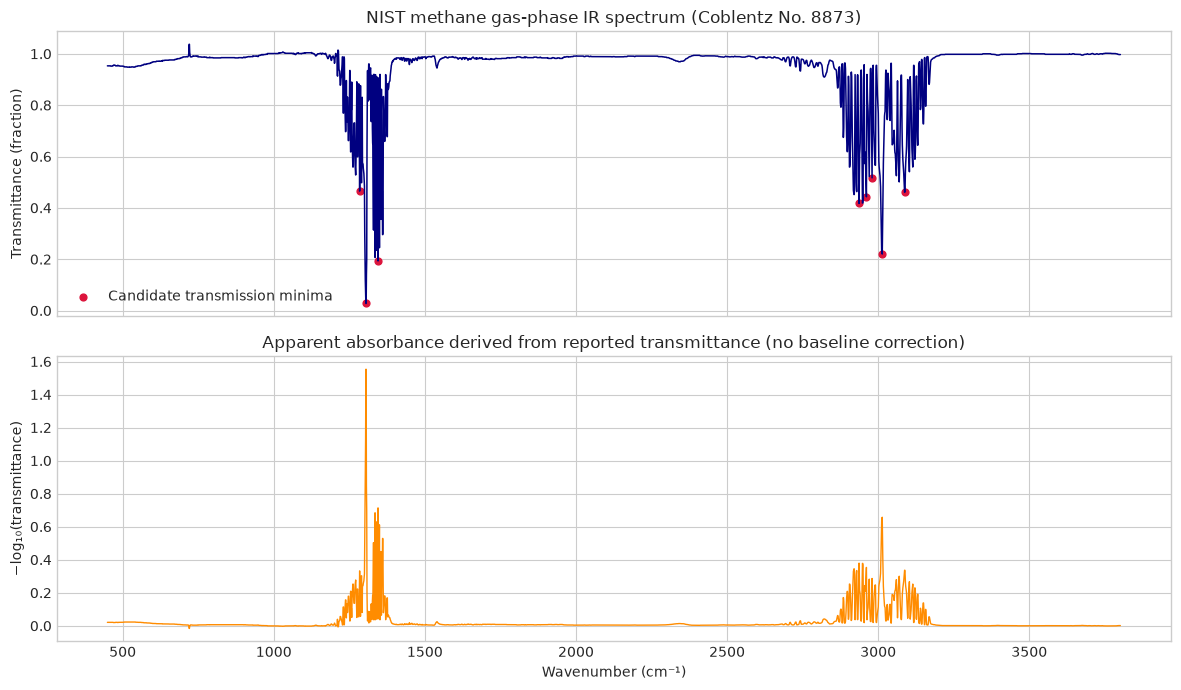

Interpretation: these are measured spectral features from a digitized reference spectrum.
They are not a time-resolved wave, spatial field, Hamiltonian density, or assigned normal modes.


In [7]:
# Analyze the measured 1D methane IR spectrum; do not invent spatial or time dimensions.
spectrum_x = raw_df['wavenumber_cm1'].to_numpy()
spectrum_t = raw_df['transmittance'].to_numpy()
spectrum_a = raw_df['apparent_absorbance'].to_numpy()

# Transmission minima are candidate absorption features, not mode assignments.
peak_indices, peak_properties = find_peaks(
    -spectrum_t,
    prominence=0.003,
    distance=20,
)
if peak_indices.size == 0:
    raise RuntimeError('No transmission minima met the selected prominence threshold.')
strongest = np.argsort(peak_properties['prominences'])[-8:][::-1]
selected_peaks = peak_indices[strongest]

print(f"Source: {chosen_source['name']}")
print(f"Measured samples: {spectrum_x.size}")
print('Axis: wavenumber (cm⁻¹); signal: transmittance (fraction)')
print('Strong candidate absorption features (cm⁻¹; transmission-minimum prominence):')
for peak_index in selected_peaks:
    position = np.where(peak_indices == peak_index)[0][0]
    print(f"  {spectrum_x[peak_index]:8.2f} cm⁻¹  {peak_properties['prominences'][position]:.4f}")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(spectrum_x, spectrum_t, color='navy', linewidth=1.1)
axes[0].scatter(spectrum_x[selected_peaks], spectrum_t[selected_peaks], color='crimson', s=24,
                label='Candidate transmission minima')
axes[0].set_title('NIST methane gas-phase IR spectrum (Coblentz No. 8873)')
axes[0].set_ylabel('Transmittance (fraction)')
axes[0].legend()

axes[1].plot(spectrum_x, spectrum_a, color='darkorange', linewidth=1.0)
axes[1].set_title('Apparent absorbance derived from reported transmittance (no baseline correction)')
axes[1].set_xlabel('Wavenumber (cm⁻¹)')
axes[1].set_ylabel('−log₁₀(transmittance)')
fig.tight_layout()
plt.show()

print('Interpretation: these are measured spectral features from a digitized reference spectrum.')
print('They are not a time-resolved wave, spatial field, Hamiltonian density, or assigned normal modes.')

## Interpreting the Generic Curve-Shape Fit

The fit is applied to transmittance versus normalized wavenumber using a damped-cosine curve. Its coefficients are not molecular parameters, and its RMSE and $R^2$ describe only the quality of that generic approximation.

- RMSE is reported in transmittance-fraction units; lower values indicate a closer curve fit to this digitized spectrum.
- $R^2$ near 1 indicates the surrogate follows much of the measured variation; values near 0 indicate little improvement over a constant mean.
- A low score is expected when a single damped cosine is used to approximate a multi-feature IR spectrum. It is not evidence for or against the underlying molecular Hamiltonian.
- Candidate transmission minima shown in the spectrum plot are not assigned normal modes. Physical interpretation requires mode-assignment evidence and a model tied to molecular structure.

## Synthetic Field Simulation (Theory Illustration)

The controls below generate a synthetic latent field using chosen equation terms and display its simulated probe signal and model energy proxy. This is not a measured methane field and its parameters are not fitted to the NIST spectrum. The spatial axes, time sampling, and coefficients are illustrative rather than calibrated molecular quantities.

In [8]:
# Synthetic equation-driven field illustration; not a reconstruction of measured molecular data.
from ipywidgets import interact, FloatSlider, IntSlider

def _prepare_base_field_for_simulation():
    if 'field4d' in globals() and isinstance(field4d, np.ndarray) and field4d.ndim == 4:
        base = np.array(field4d, dtype=float)
        return np.nan_to_num(base)
    if 'q' in globals() and isinstance(q, np.ndarray) and q.ndim == 4:
        base = np.array(q, dtype=float)
        return np.nan_to_num(base)

    # Build an explicitly synthetic latent field from the measured spectrum's signal shape.
    sig = np.asarray(y_data if 'y_data' in globals() else np.sin(np.linspace(0.0, 8.0*np.pi, 480)), dtype=float)
    sig = np.nan_to_num(sig)
    if np.std(sig) > 1e-12:
        sig = (sig - np.mean(sig)) / np.std(sig)
    nt, nx, ny, nz = 36, 10, 10, 6
    tt = np.linspace(0.0, 2.0*np.pi, nt, endpoint=False)
    xx = np.linspace(0.0, 2.0*np.pi, nx, endpoint=False)
    yy = np.linspace(0.0, 2.0*np.pi, ny, endpoint=False)
    zz = np.linspace(0.0, 2.0*np.pi, nz, endpoint=False)
    s = np.interp(np.linspace(0, len(sig) - 1, nt), np.arange(len(sig)), sig)
    base = np.zeros((nt, nx, ny, nz), dtype=float)
    for i in range(nt):
        spatial = np.cos(xx)[:, None, None] * np.cos(yy)[None, :, None] * np.cos(zz)[None, None, :]
        base[i] = s[i] * spatial
    return base

BASE_FIELD = _prepare_base_field_for_simulation()
NT_SIM, NX_SIM, NY_SIM, NZ_SIM = BASE_FIELD.shape

def _laplacian_3d(arr3):
    return (
        np.roll(arr3, -1, axis=0) + np.roll(arr3, 1, axis=0)
        + np.roll(arr3, -1, axis=1) + np.roll(arr3, 1, axis=1)
        + np.roll(arr3, -1, axis=2) + np.roll(arr3, 1, axis=2)
        - 6.0 * arr3
    )

def physical_action_simulation(
    wave_speed,
    damping_coefficient,
    restoring_stiffness,
    forcing_amplitude,
    forcing_frequency,
    forcing_phase,
    nonlinear_coupling,
    diffusion_coefficient,
    advection_speed,
    measurement_noise_std,
    snapshot_time_index,
):
    base = BASE_FIELD
    nt, nx, ny, nz = base.shape
    t = np.linspace(0.0, 2.0*np.pi, nt, endpoint=False)
    tt = t[:, None, None, None]

    xx = np.linspace(0.0, 2.0*np.pi, nx, endpoint=False)
    yy = np.linspace(0.0, 2.0*np.pi, ny, endpoint=False)
    zz = np.linspace(0.0, 2.0*np.pi, nz, endpoint=False)
    forcing_pattern = np.sin(xx)[:, None, None] * np.cos(yy)[None, :, None] * np.sin(zz)[None, None, :]

    decay = np.exp(-damping_coefficient * tt)
    oscillatory = np.cos(wave_speed * tt + forcing_phase)
    q_linear = decay * (base * oscillatory)
    q_forcing = forcing_amplitude * np.sin(forcing_frequency * tt + forcing_phase) * forcing_pattern[None, :, :, :]

    q_nl = nonlinear_coupling * (base**3) / (1.0 + np.abs(base)**2)
    grad_x = np.gradient(base, axis=1)
    q_adv = -advection_speed * grad_x

    q_sim = q_linear + q_forcing + q_nl + q_adv

    # Apply diffusion and restoring effects per time slice.
    for i in range(nt):
        q_sim[i] = q_sim[i] + diffusion_coefficient * _laplacian_3d(q_sim[i]) - restoring_stiffness * q_sim[i]

    p_sim = np.gradient(q_sim, axis=0)

    # Measurement at a representative probe location.
    ix, iy, iz = nx // 2, ny // 2, nz // 2
    rng = np.random.default_rng(1234)
    measurement = q_sim[:, ix, iy, iz] + measurement_noise_std * rng.standard_normal(nt)

    # Energy density proxy at selected time.
    k = int(np.clip(snapshot_time_index, 0, nt - 1))
    dq_dx = np.gradient(q_sim[k], axis=0)
    dq_dy = np.gradient(q_sim[k], axis=1)
    dq_dz = np.gradient(q_sim[k], axis=2)
    energy_density = 0.5 * p_sim[k]**2 + 0.5 * (dq_dx**2 + dq_dy**2 + dq_dz**2) + 0.5 * restoring_stiffness * q_sim[k]**2

    # Frequency-domain measurement power.
    spec = np.fft.rfft(measurement - np.mean(measurement))
    freq = np.fft.rfftfreq(nt, d=1.0)
    power = np.abs(spec)**2

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    axes[0].plot(t, measurement, color='navy', lw=2)
    axes[0].set_title('Synthetic Model Signal at Probe')
    axes[0].set_xlabel('time')
    axes[0].set_ylabel('measurement')

    im = axes[1].imshow(energy_density[:, :, nz // 2], origin='lower', cmap='magma', aspect='auto')
    axes[1].set_title(f'Synthetic model energy proxy (t index={k})')
    axes[1].set_xlabel('y-index')
    axes[1].set_ylabel('x-index')
    fig.colorbar(im, ax=axes[1], fraction=0.046)

    axes[2].plot(freq, power, color='crimson', lw=2)
    axes[2].set_title('Synthetic model-signal power spectrum')
    axes[2].set_xlabel('frequency')
    axes[2].set_ylabel('power')

    plt.tight_layout()
    plt.show()

    print('Energy mean:', float(np.mean(energy_density)), '| Energy max:', float(np.max(energy_density)))
    print('Measurement std:', float(np.std(measurement)), '| Dominant frequency bin:', float(freq[np.argmax(power)]))

interact(
    physical_action_simulation,
    wave_speed=FloatSlider(value=1.3, min=0.2, max=4.0, step=0.05),
    damping_coefficient=FloatSlider(value=0.08, min=0.0, max=1.2, step=0.01),
    restoring_stiffness=FloatSlider(value=0.6, min=0.05, max=3.0, step=0.05),
    forcing_amplitude=FloatSlider(value=0.7, min=0.0, max=3.0, step=0.05),
    forcing_frequency=FloatSlider(value=1.8, min=0.1, max=8.0, step=0.05),
    forcing_phase=FloatSlider(value=0.0, min=-np.pi, max=np.pi, step=0.05),
    nonlinear_coupling=FloatSlider(value=0.15, min=-1.0, max=1.0, step=0.02),
    diffusion_coefficient=FloatSlider(value=0.06, min=0.0, max=0.5, step=0.01),
    advection_speed=FloatSlider(value=0.12, min=-1.0, max=1.0, step=0.02),
    measurement_noise_std=FloatSlider(value=0.02, min=0.0, max=0.5, step=0.01),
    snapshot_time_index=IntSlider(value=8, min=0, max=max(1, NT_SIM - 1), step=1),
)

interactive(children=(FloatSlider(value=1.3, description='wave_speed', max=4.0, min=0.2, step=0.05), FloatSlid…

<function __main__.physical_action_simulation(wave_speed, damping_coefficient, restoring_stiffness, forcing_amplitude, forcing_frequency, forcing_phase, nonlinear_coupling, diffusion_coefficient, advection_speed, measurement_noise_std, snapshot_time_index)>

## Interactive Synthetic Model Controls

Use these sliders to see how the illustrative model changes. The generated signal is not a prediction of, or fit to, the methane IR measurements above.


In [9]:
def interactive_plot(p1, p2, p3, p4):
    y_sim = model_function(x_data, p1, p2, p3, p4)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(x_data, y_data, s=10, alpha=0.45, label='Empirical data')
    ax.plot(x_data, y_sim, color='navy', linewidth=2.0, label='Simulation')
    ax.set_title(f'{DOMAIN_TITLE}: generic curve-shape parameter sweep')
    ax.set_xlabel('Normalized wavenumber (0–1)')
    ax.set_ylabel('Transmittance (fraction)')
    ax.legend()
    plt.show()

interact(
    interactive_plot,
    p1=widgets.FloatSlider(value=float(popt[0]), min=-2*abs(float(popt[0]))-1, max=2*abs(float(popt[0]))+1, step=0.01),
    p2=widgets.FloatSlider(value=float(popt[1]), min=0.0, max=max(1.0, 3*abs(float(popt[1]))+1), step=0.01),
    p3=widgets.FloatSlider(value=float(popt[2]), min=-20.0, max=20.0, step=0.05),
    p4=widgets.FloatSlider(value=float(popt[3]), min=float(np.min(y_data))-2, max=float(np.max(y_data))+2, step=0.01),
);


interactive(children=(FloatSlider(value=0.0723880502685025, description='p1', max=1.144776100537005, min=-1.14…

## Optional dimensionality-reduction benchmark: truncated HOSVD

A higher-order SVD (HOSVD) approximates a tensor by a small core and one factor matrix per mode. The next cell benchmarks a truncated HOSVD of `BASE_FIELD`, the synthetic 4D seed tensor, and reports reconstruction error, encoded-storage ratio, and elapsed compression time. It does **not** replace or modify the full-rank simulation. HOSVD only saves memory for later use if downstream calculations stay in the compressed representation; forming and reconstructing a dense tensor still has the original storage cost. The default tensor has just 21,600 float64 entries (~0.17 MB) and is constructed as a separable product by design, so compression here is an illustration, not evidence of compressibility in measured or molecular data. Tiny differences between measured reconstruction error and the reported HOSVD truncation bound are floating-point round-off.

DMD is a different tool: it fits a linear evolution operator to sequential state snapshots and can provide a low-rank surrogate when there is a meaningful, sufficiently sampled trajectory. The current synthetic routine evaluates an algebraic field and one stencil rather than time-stepping a physical molecular trajectory, and PySCF computes a stationary optimized electronic state. Thus DMD would not be physically justified on these outputs. Neither post-hoc HOSVD nor DMD reduces the NIST fit or PySCF SCF cost as currently implemented.

In [12]:
from time import perf_counter

def _mode_product(tensor, matrix, mode):
    moved = np.moveaxis(tensor, mode, 0)
    product = matrix @ moved.reshape(moved.shape[0], -1)
    shape = (matrix.shape[0],) + moved.shape[1:]
    return np.moveaxis(product.reshape(shape), 0, mode)

def truncated_hosvd(tensor, relative_tolerance=1e-3):
    if tensor.ndim < 2 or not np.isfinite(tensor).all():
        raise ValueError('HOSVD requires a finite tensor with at least two modes.')
    if not 0 < relative_tolerance < 1:
        raise ValueError('relative_tolerance must be between 0 and 1.')

    total_energy = float(np.vdot(tensor, tensor).real)
    factors = []
    discarded_energy = 0.0
    for mode in range(tensor.ndim):
        unfolding = np.moveaxis(tensor, mode, 0).reshape(tensor.shape[mode], -1)
        left, singular_values, _ = np.linalg.svd(unfolding, full_matrices=False)
        mode_energy = singular_values**2
        if total_energy == 0.0:
            rank = 1
        else:
            allowed_discard = (relative_tolerance**2 / tensor.ndim) * total_energy
            target_energy = max(float(mode_energy.sum()) - allowed_discard, 0.0)
            rank = min(int(np.searchsorted(np.cumsum(mode_energy), target_energy) + 1), len(singular_values))
        discarded_energy += float(mode_energy[rank:].sum())
        factors.append(left[:, :rank])

    core = tensor
    for mode, factor in enumerate(factors):
        core = _mode_product(core, factor.T, mode)
    error_bound = np.sqrt(discarded_energy / max(total_energy, np.finfo(float).tiny))
    return core, factors, float(error_bound)

tensor = np.asarray(BASE_FIELD, dtype=np.float64)
start = perf_counter()
hosvd_core, hosvd_factors, hosvd_error_bound = truncated_hosvd(tensor)
compression_seconds = perf_counter() - start

start = perf_counter()
reconstruction = hosvd_core
for mode, factor in enumerate(hosvd_factors):
    reconstruction = _mode_product(reconstruction, factor, mode)
reconstruction_seconds = perf_counter() - start
relative_error = float(np.linalg.norm(tensor - reconstruction) / max(np.linalg.norm(tensor), np.finfo(float).tiny))
full_bytes = tensor.nbytes
encoded_bytes = hosvd_core.nbytes + sum(factor.nbytes for factor in hosvd_factors)

print('Tensor shape:', tensor.shape)
print('Truncated multilinear ranks:', tuple(factor.shape[1] for factor in hosvd_factors))
print('Core shape:', hosvd_core.shape)
print(f'Relative Frobenius reconstruction error: {relative_error:.3e} (bound {hosvd_error_bound:.3e})')
print(f'Encoded storage: {encoded_bytes:,} / {full_bytes:,} bytes ({encoded_bytes / full_bytes:.3%} of dense)')
print(f'HOSVD compression time: {compression_seconds:.6f} s; reconstruction time: {reconstruction_seconds:.6f} s')
print('Full-rank BASE_FIELD remains unchanged; timings are illustrative for this tiny tensor.')

Tensor shape: (36, 10, 10, 6)
Truncated multilinear ranks: (1, 1, 1, 1)
Core shape: (1, 1, 1, 1)
Relative Frobenius reconstruction error: 3.815e-15 (bound 3.506e-15)
Encoded storage: 504 / 172,800 bytes (0.292% of dense)
HOSVD compression time: 0.021558 s; reconstruction time: 0.000302 s
Full-rank BASE_FIELD remains unchanged; timings are illustrative for this tiny tensor.


## 3D orbital shapes, selected bond overlaps, and delocalized pi electrons

Run the next cell. The model lives in [orbital_explorer.py](orbital_explorer.py), alongside this notebook.
Install the repository requirements in the **notebook kernel**, not a different terminal environment.
If imports fail, run `%pip install "plotly>=5.20" "scikit-image>=0.22"` in that kernel.

### Where are the clovers?

The default **d orbital gallery** displays each orbital in its own rotatable panel:
- **dxy, dxz, dyz, dx²−y²:** four-lobed clovers, with alternating wavefunction phase.
- **dz²:** two axial lobes and an equatorial torus; it is not a four-leaf clover.
- **s:** a sphere. **p:** two-lobed dumbbells. **f:** more complicated lobes/nodal surfaces.

Choose **Atomic orbitals — focus atom**, then an **Individual AO**, to inspect just one orbital.
In isolated gallery presets, local and world axes coincide before a twist.
**Lobe fraction** sets the isosurface at a fraction of that field's peak magnitude;
it is not a probability contour. Higher values shrink the visible lobes.
Blue and orange indicate opposite signs of the wavefunction, **not positive/negative charge**.
Superposing every orbital obscures clovers, so the separate gallery is the recommended starting point.

### Which orbitals overlap to make a bond?

Select **ethylene**, choose the **pi** entry in **Bond / overlap**, and compare:
1. **Bond contributors:** the two unhybridized pz atomic orbitals, with their facing phases aligned.
2. **Bonding MOs:** reinforcing side-on overlap above and below the C–C axis.
3. **Antibonding MOs:** the corresponding extra node between the atoms.
4. **Overlap density:** green = locally reinforcing; purple = locally cancelling after phase alignment.

The selected atom/orbital pair is named in the controls, hover labels, and explanation below the plot.
Sigma bonds use head-on overlap along the internuclear axis (s–s, s–hybrid, or hybrid–hybrid).
Ethylene has five sigma bonds and one localized pi bond; acetylene has three sigma and two pi bonds.
Rotate one carbon's p orbitals with **Focus twist**: orthogonal p orbitals lose their pi overlap.
Hydrogen bonds are separate dashed donor–H···acceptor contacts, not sigma/pi covalent bonds.
They require an N/O/F donor/acceptor, an available lone pair, H···A distance 1.4–2.6 Å and angle >120°.
The HF-chain and four-H₂ presets still demonstrate up to four interacting molecules.

### Pi bonding is not the same as resonance

A pi bond arises from **side-on orbital overlap**, not sigma bonds resonating.
**Resonance** describes electrons shared across a conjugated network of three or more p orbitals;
it does not mean alternating bonds physically switch back and forth.
Choose **benzene** to see the six connected pz orbitals sharing six pi electrons.
The default purple surface is the total occupied pi electron density, Σ nᵢ|ψᵢ|².
Switch to **Delocalized pi — selected molecular orbital** and choose an MO to see its phases and nodes.
Three delocalized MOs are occupied; the other three are empty. Purple dotted ring contacts identify the
shared p network rather than six additional localized electron-pair bonds.

### Model and limits

Atomic surfaces use real spherical harmonics and normalized Slater-type radial functions.
The gallery has all five d and all seven f orbitals. Hybrid sets include sp, sp², sp³,
sp³d, sp³d² and the hypothetical sp³d³f set, plus unhybridized leftovers.
Hybrids mix basis functions; an spd hybrid is **not** a pure d clover.
Localized overlap assignments are greedy, valence-limited teaching approximations; they are not
a chemical structure solver. Angular Fourier components classify sigma/pi/delta/phi symmetry.
Conjugated one-electron p networks reuse each p orbital across its neighbours and solve the full
generalized extended-Hückel eigenproblem HC = SCE, rather than assigning exclusive pairwise pi bonds.
The same generalized two-centre problem supplies the localized MO coefficients and energy levels.

**This is a qualitative visualization, not a quantum-chemistry prediction.**
The d/f and spd/spdf demonstrations do not prove d/f participation in real PF₅/SF₆ or sulfur bonds.
Energies are illustrative; electron correlation, geometry optimization, dispersion, excited-state
populations and quantitative hydrogen-bond energetics are outside this model.
If the normal Plotly renderer fails, an explicit notice precedes a self-contained HTML fallback;
it does not need a CDN connection.


In [13]:
# Load the editable, tested 3D model alongside this notebook.
from pathlib import Path
import importlib.util

_candidates = [candidate for parent in (Path.cwd(), *Path.cwd().parents)
               for candidate in (parent / 'orbital_explorer.py',
                                 parent / 'projects/16_molecular_waves/orbital_explorer.py')]
_model_path = next((path for path in _candidates if path.is_file()), None)
if _model_path is None:
    raise FileNotFoundError('Run this notebook inside the repository containing orbital_explorer.py.')
_spec = importlib.util.spec_from_file_location('molecular_orbital_explorer', _model_path)
if _spec is None or _spec.loader is None:
    raise ImportError(f'Cannot load orbital explorer from {_model_path}')
explorer = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(explorer)
explorer.show_explorer()


## Equation-driven atomic and molecular orbital explorer

Run the next cell, enter a formula or stoichiometric equation, and click **Parse equation**.
Examples: `2 H2 + O2 -> 2 H2O`, `Fe^2+ + 2 Cl^- -> FeCl2`, or `C6H6`.
The table checks atom and charge conservation; it does **not** automatically balance equations.
Positive integer coefficients, nested `( )` / `[ ]` groups, hydrates such as `CuSO4·5H2O`,
Unicode subscripts, `(s)/(l)/(g)/(aq)` phases and caret charges (`NH4^+`, `SO4^2-`) are supported.

### Atomic view
Choose a species, an element, an occupied subshell, and an individual real s/p/d/f orbital.
The 118 element symbols are recognized. Electron configurations are **Aufbau estimates with common
ground-state exceptions**, not a spectroscopic database. Occupancies illustrate Hund's rule.
Monatomic ions adjust the electron count (e.g. Fe^2+ removes 4s electrons first); polyatomic ions
show neutral isolated-atom references because their charge cannot be assigned uniquely to atoms.
Bare nuclei have no occupied orbitals. Atomic ion views support charges -2 through Z and at most 118 electrons.
The surfaces use hydrogenic radial functions with their radial nodes, plus real spherical harmonics.
**Atomic Z effective** is a manually selected size parameter, not an inferred screening calculation;
changing it does not change electron populations. Blue/orange are wavefunction phases, not charge.
High surface thresholds can hide small inner lobes; this is not a self-consistent many-electron calculation.

### Molecular view
Known neutral templates: **H2, N2, C2H4, C2H2, H2O, HF, C6H6, PF5, SF6**.
Choose bond contributors, bonding/antibonding MOs, overlap, or delocalized pi density/MOs for benzene.
A formula does not identify an isomer or geometry. Missing templates (including O2) require
**Explicit structure** rows and **Apply structure**; no structure is guessed from the equation.
Each row is `element orbital-set x y z [aim-x aim-y aim-z [twist-degrees]]`, with coordinates in angstroms.
Orbital sets use `s`, `p`, `d`, `f`, `sp`, `sp2`, `sp3`, `sp3d`, `sp3d2`, or `sp3d3f`.
The aim vector defaults to +x; set it explicitly to orient directional bonding lobes.
For example, a custom H2 structure is:
```text
H s 0 0 0 1 0 0
H s 0.74 0 0 -1 0 0
```
Composition must match the selected species. The fast qualitative molecular model has parameters
only for **H, C, N, O, F, P, S, Cl**; it does not optimize geometry or calculate self-consistent density.
Custom molecular views support up to 24 atoms and a 30 angstrom span to keep the grid interactive.
Coefficients multiply atom counts, not rendered molecule copies or electrons.

### Optional self-consistent PySCF DFT
The separate **Run PySCF DFT + optimize** control optimizes the supplied starting geometry, then computes
total electron density, signed molecular orbitals, and total DFT energy. Initial `def2-SVP` support is
H through Kr (Z ≤ 36), up to 24 atoms. Install optional packages in this notebook kernel with
`%pip install -r projects/16_molecular_waves/requirements-quantum-chemistry.txt`, then restart the kernel.
Solver geometry rows are `element x y z` in angstroms; set spin multiplicity explicitly. A formula does
not determine geometry or isomer. Optimization minimizes the DFT energy surface, including nuclear
repulsion, rather than applying hand-set bond-angle penalties. Optimization is local; this is not
a bond-dissociation energy or experimental electron-density measurement. Reported contacts and angles
use a covalent-radius heuristic,
not a bond-order analysis. The viewer loads [equation_explorer.py](equation_explorer.py),
[orbital_explorer.py](orbital_explorer.py), and the optional
[quantum_chemistry.py](quantum_chemistry.py); keep these files alongside the notebook.


In [14]:
from pathlib import Path
import importlib.util

_equation_candidates = [candidate for parent in (Path.cwd(), *Path.cwd().parents)
                        for candidate in (parent / 'equation_explorer.py',
                                          parent / 'projects/16_molecular_waves/equation_explorer.py')]
_equation_path = next((path for path in _equation_candidates if path.is_file()), None)
if _equation_path is None:
    raise FileNotFoundError('Run inside the repository containing equation_explorer.py.')
_equation_spec = importlib.util.spec_from_file_location('stoichiometric_orbitals', _equation_path)
if _equation_spec is None or _equation_spec.loader is None:
    raise ImportError(f'Cannot load equation explorer from {_equation_path}')
equation_model = importlib.util.module_from_spec(_equation_spec)
_equation_spec.loader.exec_module(equation_model)
equation_viewer = equation_model.show_equation_explorer()
